# Formation channels for SMC and LMC metallicity populations

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
from scipy.stats import gaussian_kde
from posydon.utils.common_functions import convert_metallicity_to_string
from posydon.popsyn.distributions import PowerLawPeriod

from wr_population.paths import FIGURE_DIR, EXTRA_FIGURE_DIR
from wr_population.io import load_metallicity, LMC_binary_periods, SMC_binary_periods
from wr_population.classification import (classify_WR, make_binary_mask,
                                          formation_channel_masks, CHANNEL_COLOURS)
from wr_population.plotting import METALLICITY_COLOURS, plot_period_histogram

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))
COLORS = METALLICITY_COLOURS

LOG_P_MIN = -1.0
LOG_P_MAX = 6.0

from wr_population.plotting import use_posydon_style
use_posydon_style()


In [2]:
metallicities = [0.1, 0.2, 0.45]  # in units of Zsun

WR_data = {Z: load_metallicity(Z) for Z in metallicities}

# Load observations

In [3]:
print(LMC_binary_periods())

[17.99  2.2   1.9   2.82 31.69 37.59  5.21  2.11  2.75  2.77]


## LMC

In [4]:
def plot_observations_LMC(ax):
    """Observed LMC period distribution; the density is scaled by 0.1 for the comparison."""
    plot_period_histogram(ax, LMC_binary_periods(), n_bins=40, log_p_range=(LOG_P_MIN, LOG_P_MAX),
                          scale=0.1, label='Observations')

## SMC

In [5]:
def plot_observations_SMC(ax):
    """Observed SMC period distribution; the density is scaled by 0.1 for the comparison."""
    plot_period_histogram(ax, SMC_binary_periods(), n_bins=40, log_p_range=(LOG_P_MIN, LOG_P_MAX),
                          scale=0.1, label='Observations')

## Plotting

In [6]:
colours = CHANNEL_COLOURS

WNL: 1.0


Stable (S1): 45.572%


Stable (S2): 18.866%
Unstable (S1): 1.682%


Unstable (S2): 4.600%


No MT (S1): 16.369%


...

WNL: 1.0


Stable (S1): 46.780%
Stable (S2): 15.718%


Unstable (S1): 4.693%
Unstable (S2): 4.049%


No MT (S1): 20.629%


No MT (S2): 7.320%
Reverse Stable (S1): 0.812%


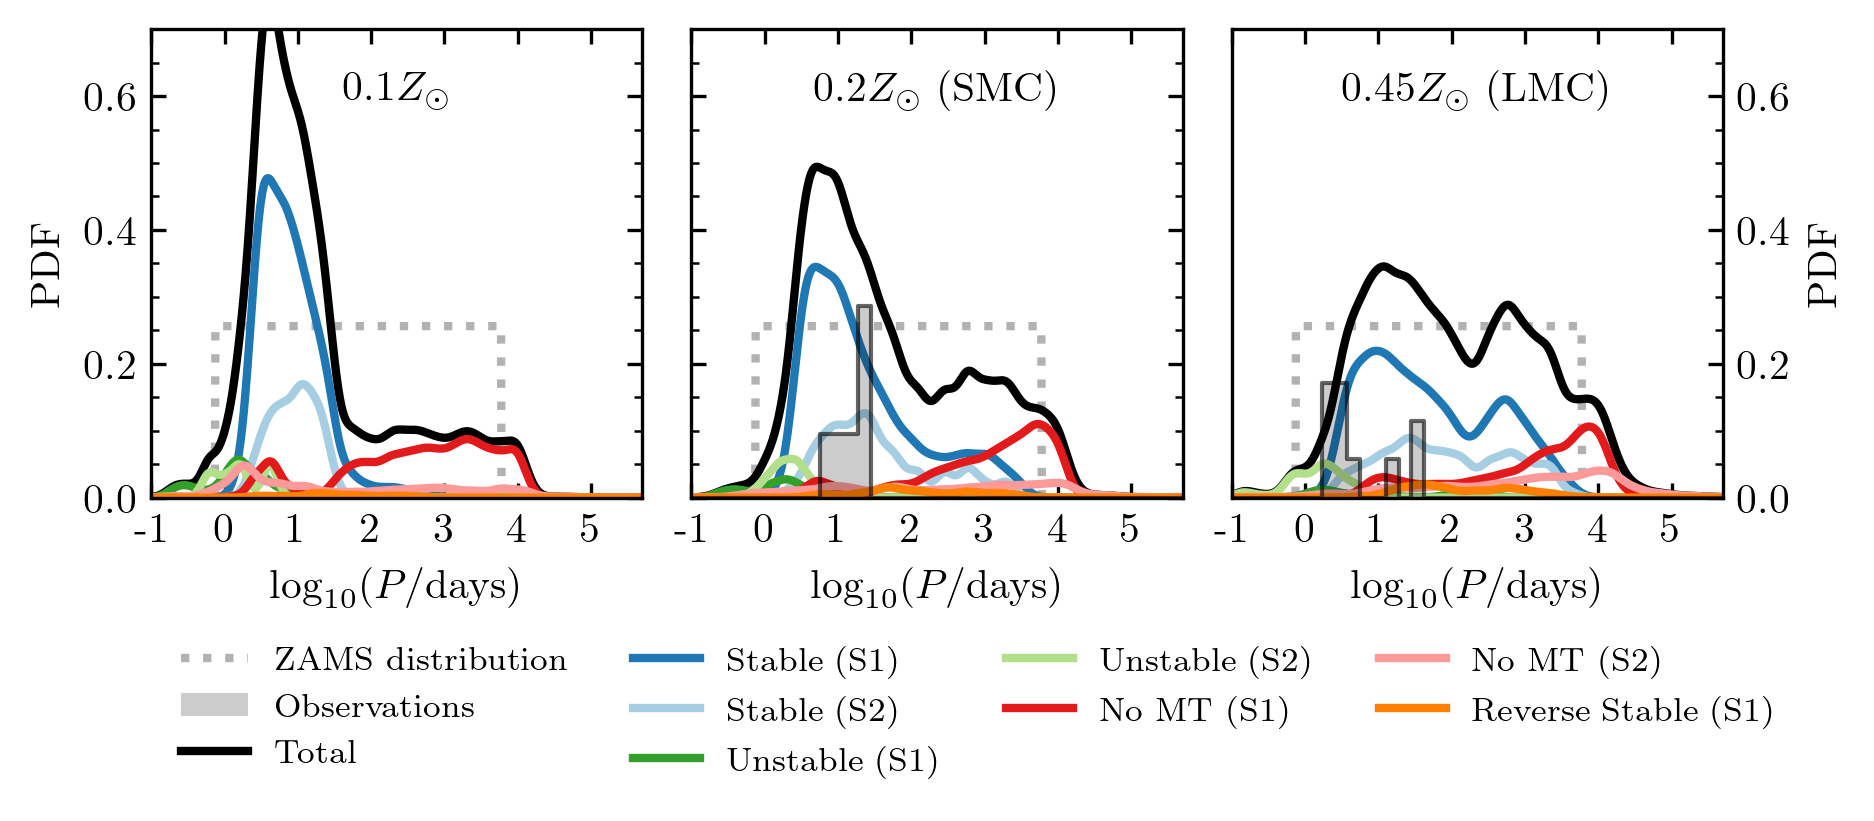

In [7]:

metallicity = 0.45
met_str = convert_metallicity_to_string(metallicity)

channel_masks = formation_channel_masks(WR_data[metallicity], metallicity)


fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

mask = make_binary_mask(WR_data[metallicity])
WNL, WNE, WC = classify_WR(WR_data[metallicity])

MT_interactions = channel_masks



flatP = PDF_logP.pdf(10**x_eval)
axes[2].plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

period_array = WR_data[metallicity]['period']
weights = WR_data[metallicity]['weight'] * WR_data[metallicity]['model_weight']


# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)


# plot observations
plot_observations_LMC(axes[2])


# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout
axes[2].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[2].set_xscale('log')
axes[2].set_xlim(1e-1, 5e5)
axes[2].set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
axes[2].set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
axes[2].set_ylim(0, 0.7)
axes[2].grid(False)
#axes[2].grid(True, which='major', ls='--', alpha=0.3)
    
axes[2].set_ylabel('PDF')

# move y-axis to the right for the second subplot
axes[2].yaxis.set_label_position("right")
axes[2].yaxis.tick_right()

#axes[2].legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

# SMC population
print("SMC population")

metallicity = 0.2
met_str = convert_metallicity_to_string(metallicity)

channel_masks = formation_channel_masks(WR_data[metallicity], metallicity)

mask = make_binary_mask(WR_data[metallicity])
WNL, WNE, WC = classify_WR(WR_data[metallicity])

MT_interactions = channel_masks


flatP = PDF_logP.pdf(10**x_eval)
axes[1].plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

period_array = WR_data[metallicity]['period']
weights = WR_data[metallicity]['weight'] * WR_data[metallicity]['model_weight']


# plot observations
plot_observations_SMC(axes[1])


# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)



# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout
axes[1].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[1].set_xscale('log')
axes[1].set_xlim(1e-1, 5e5)
axes[1].set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
axes[1].set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
axes[1].set_ylim(0, 0.7)
axes[1].grid(False)
#axes[1].grid(True, which='major', ls='--', alpha=0.3)

# turn of y-axis for the second subplot
axes[1].set_yticklabels([])

axes[1].legend(bbox_to_anchor=(-1.1, -0.25), loc='upper left', ncol=4)


metallicity = 0.1
met_str = convert_metallicity_to_string(metallicity)

channel_masks = formation_channel_masks(WR_data[metallicity], metallicity)

mask = make_binary_mask(WR_data[metallicity])
WNL, WNE, WC = classify_WR(WR_data[metallicity])

MT_interactions = channel_masks


flatP = PDF_logP.pdf(10**x_eval)
axes[0].plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

period_array = WR_data[metallicity]['period']
weights = WR_data[metallicity]['weight'] * WR_data[metallicity]['model_weight']



# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    
    # plot histogram 
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
    total += fraction
    print(f"{label}: {fraction*100:.3f}%")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])


# Housekeeping for layout
axes[0].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[0].set_xscale('log')
axes[0].set_xlim(1e-1, 5e5)
axes[0].set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
axes[0].set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
axes[0].set_ylim(0, 0.7)
axes[0].grid(False)
#axes[1].grid(True, which='major', ls='--', alpha=0.3)
    
axes[0].set_ylabel('PDF')

#axes[0].legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=4)
plt.subplots_adjust(wspace=0.1,)

axes[0].text(0.5, 0.85, '$0.1Z_\odot$', transform=axes[0].transAxes, ha='center')
axes[1].text(0.5, 0.85, '$0.2Z_\odot$ (SMC)', transform=axes[1].transAxes, ha='center')
axes[2].text(0.5, 0.85, '$0.45Z_\odot$ (LMC)', transform=axes[2].transAxes, ha='center')


figure_paths = str(FIGURE_DIR) + '/'
plt.savefig(figure_paths + 'pdf/SMC_LMC_WR_period_distributions_MT.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/SMC_LMC_WR_period_distributions_MT.png', bbox_inches='tight', dpi=300)
plt.show()

# observations have been rescale with 0.1 factor